# Acondicionamiento y corrección de los datos — OT Consulting (RH)
**Reto Etapa 3** · Franco Varela Villegas · A01199186

Este cuaderno corre el pipeline `src/acondicionamiento_rh.py` contra los 7 archivos reales que exporta el sistema de RH
y muestra, método por método (M1–M14), qué se corrigió y con qué resultado.

**Principio rector:** el acondicionamiento no borra ni inventa registros. Corrige formato, reconstruye llaves, nulifica
centinelas y deja bandera de calidad. Lo que no cumple una regla se marca y se excluye del indicador, pero se conserva.

> Versión pública: no se muestran nombres, sueldos individuales ni datos de contacto. Los archivos fuente y la carpeta
> `salida/` no se versionan.

In [1]:
import sys, sqlite3, warnings
sys.path.insert(0, '../src')
import numpy as np, pandas as pd, matplotlib.pyplot as plt
import acondicionamiento_rh as ac, catalogos as cat
warnings.filterwarnings('ignore')
pd.set_option('display.max_columns', 60); pd.set_option('display.width', 220); pd.set_option('display.max_colwidth', 70)

TINTA, CARMIN, BRUMA = '#17171A', '#D62F5C', '#C9C5C2'
plt.rcParams.update({'figure.dpi': 110, 'axes.spines.top': False, 'axes.spines.right': False,
                     'axes.edgecolor': BRUMA, 'axes.titleweight': 'bold', 'axes.titlelocation': 'left', 'font.size': 10})

CORTE = '2026-11-20'                      # parámetro del cuaderno
tablas, raw = ac.acondicionar('../datos', CORTE)
ruta, validaciones = ac.guardar(tablas, raw, '../salida')
con = sqlite3.connect(ruta)
sql = lambda q: pd.read_sql(q, con)
col, asig, act = tablas['colaborador'], tablas['asignacion'], tablas['activo']
log = tablas['log_correcciones']
print('Base generada:', ruta, '· corte', CORTE)

Base generada: ../salida/otc_rh.db · corte 2026-11-20


## 1. Entrada y salida
Los 7 archivos entran con las filas que exporta el sistema; ninguna tabla pierde registros.

In [2]:
pd.DataFrame([
    ('Colaboradores', len(raw['colaboradores']), 'colaborador_acondicionado', len(col), col.shape[1]),
    ('Asignaciones', len(raw['asignaciones']), 'asignacion_acondicionada', len(asig), asig.shape[1]),
    ('Clientes y proyectos', len(raw['clientes']), 'proyecto_acondicionado', len(tablas['proyecto']), tablas['proyecto'].shape[1]),
    ('Clientes y proyectos', len(raw['clientes']), 'cliente_acondicionado', len(tablas['cliente']), tablas['cliente'].shape[1]),
    ('Activos', len(raw['activos']), 'activo_acondicionado', len(act), act.shape[1]),
    ('Departamentos', len(raw['departamentos']), 'departamento_acondicionado', len(tablas['departamento']), tablas['departamento'].shape[1]),
    ('Habilidades', len(raw['habilidades']), 'habilidad_acondicionada', len(tablas['habilidad']), tablas['habilidad'].shape[1]),
    ('Matriz de habilidades', len(raw['matriz']), 'matriz_habilidad_long', len(tablas['matriz_habilidad']), tablas['matriz_habilidad'].shape[1]),
], columns=['archivo fuente', 'filas fuente', 'tabla acondicionada', 'filas', 'columnas'])

,archivo fuente,filas fuente,tabla acondicionada,filas,columnas
0,Colaboradores,107,colaborador_acondicionado,107,72
1,Asignaciones,31,asignacion_acondicionada,31,25
2,Clientes y proyectos,12,proyecto_acondicionado,12,13
3,Clientes y proyectos,12,cliente_acondicionado,8,7
4,Activos,123,activo_acondicionado,123,19
5,Departamentos,6,departamento_acondicionado,6,8
6,Habilidades,71,habilidad_acondicionada,71,7
7,Matriz de habilidades,54,matriz_habilidad_long,1529,7


## 2. M1 · Normalización de texto y M2 · Nulificación de centinelas
`PENDIENTE`, `Indefinido`, `Sin asignar`, `1990-01-01` y similares ocupan el lugar de un dato que no existe.
Se convierten a nulo y se deja una bandera `falta_*`. La completitud *aparente* de la columna era engañosa.

In [3]:
cal = tablas['calidad_datos']
cal[cal.centinelas > 0].sort_values('centinelas', ascending=False)[
    ['tabla', 'columna_fuente', 'registros', 'completitud_aparente_pct', 'centinelas', 'indice_completitud']]

,tabla,columna_fuente,registros,completitud_aparente_pct,centinelas,indice_completitud
13,colaborador,Aviso: Manutención,107,100.0,97,9.3
12,colaborador,Aviso: Infonavit,107,100.0,95,11.2
10,colaborador,Doc: Contrato,107,100.0,92,14.0
11,colaborador,Doc: Foto,107,100.0,72,32.7
26,activo,Costo,123,100.0,70,43.1
6,colaborador,Puesto,107,100.0,48,53.3
28,activo,Fecha Inicio,123,74.0,35,44.7
27,activo,Colaborador Asignado,123,100.0,32,74.0
16,asignacion,Rol Asignado,31,100.0,29,6.5
7,colaborador,Sueldo Total Integrado,107,100.0,25,76.6


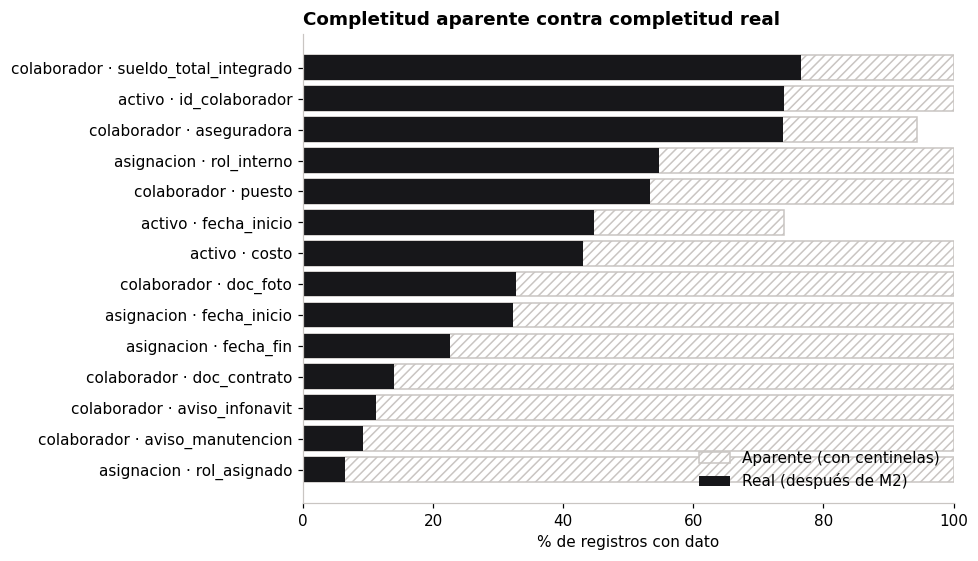

In [4]:
d = cal[(cal.centinelas > 0)].sort_values('indice_completitud')
fig, ax = plt.subplots(figsize=(9, 5.2))
y = np.arange(len(d))
ax.barh(y, d.completitud_aparente_pct, color='white', edgecolor=BRUMA, hatch='////', label='Aparente (con centinelas)')
ax.barh(y, d.indice_completitud, color=TINTA, label='Real (después de M2)')
ax.set_yticks(y, d.tabla + ' · ' + d.columna); ax.set_xlabel('% de registros con dato'); ax.set_xlim(0, 100)
ax.set_title('Completitud aparente contra completitud real'); ax.legend(frameon=False, loc='lower right')
plt.tight_layout(); plt.show()

**Resultado:** las columnas que parecían llenas al 100% en realidad tienen entre 7% y 77% de dato útil. Lo rayado era relleno.

## 3. M3 · Catálogos
Los valores de texto libre se llevan a su forma canónica con un diccionario de equivalencias escrito en `src/catalogos.py`.
`rapidfuzz` solo propone candidatos para lo que no esté en el diccionario; nunca asigna solo.

In [5]:
def grafias(nombre, antes, despues):
    return {'campo': nombre, 'grafías antes': antes.dropna().nunique(), 'valores después': despues.dropna().nunique()}
pd.DataFrame([
    grafias('Ciudad', raw['colaboradores']['Ciudad'], col.ciudad),
    grafias('Aseguradora (SGMM)', raw['colaboradores']['SGMM'], col.aseguradora),
    grafias('Marca de equipo', raw['activos']['Marca'], act.marca),
    grafias('Industria', raw['clientes']['Industria'], tablas['cliente'].industria),
    grafias('Tecnología de habilidad', raw['habilidades']['tecnologia'], tablas['habilidad'].tecnologia),
])

,campo,grafías antes,valores después
0,Ciudad,25,22
1,Aseguradora (SGMM),10,3
2,Marca de equipo,12,5
3,Industria,5,4
4,Tecnología de habilidad,6,6


In [6]:
print('Marca antes :', raw['activos']['Marca'].value_counts().to_dict())
print('Marca después:', act.marca.value_counts().to_dict())
print()
print('Valores fuera de catálogo que quedaron como propuesta:', len(tablas['propuestas_catalogo']))

Marca antes : {'DELL': 54, 'HP': 23, 'LENOVO': 17, 'ACER': 8, 'Lenovo': 5, 'DELL ': 4, 'HP ': 3, 'Dell': 3, 'LENOVO ': 2, 'ASUS': 2, 'Dell ': 1, 'Acer': 1}
Marca después: {'Dell': 62, 'HP': 26, 'Lenovo': 24, 'Acer': 9, 'Asus': 2}

Valores fuera de catálogo que quedaron como propuesta: 0


## 4. M4 · Tipificación y M11 · Imputación controlada
Fechas con `errors='coerce'`, montos numéricos y documentación a `1 / 0 / nulo`.
**No se imputa:** un sueldo o un costo en \$0 es dato desconocido, no un cero. Pasa a nulo con bandera.

In [7]:
tot = ac.a_monto(raw['colaboradores']['Sueldo Total Integrado'])
cst = ac.a_monto(raw['activos']['Costo'])
pd.DataFrame([
    ('Sueldo Total Integrado', int((tot == 0).sum()), int(col.sueldo_total_integrado.isna().sum()), int((col.sueldo_total_integrado == 0).sum()), int(col.falta_sueldo.sum())),
    ('Costo de equipo', int((cst == 0).sum()), int(act.costo.isna().sum()), int((act.costo == 0).sum()), int(act.falta_costo.sum())),
], columns=['campo', 'en $0 en la fuente', 'nulos después', 'en $0 después', 'con bandera de faltante'])

,campo,en $0 en la fuente,nulos después,en $0 después,con bandera de faltante
0,Sueldo Total Integrado,25,25,0,5
1,Costo de equipo,70,70,0,70


La bandera `falta_sueldo` solo se prende en activos de plantilla (5): en las bajas el sueldo en \$0 también queda nulo, pero ya no es un dato que RH deba capturar.

## 5. M5 · Reconstrucción de llaves
- **Activos → colaborador:** la liga venía por nombre completo. Se resuelve a `id_colaborador` (exacta primero; difusa con bandera).
- **Proyecto:** no tenía código. Se genera `id_proyecto` desde (cliente, proyecto) normalizados.
- **Asignaciones → proyecto / cliente:** llegaban por texto; ahora por ID.

In [8]:
print('Activos ligados por ID            :', int(act.id_colaborador.notna().sum()), 'de', len(act))
print('  · liga exacta                   :', int((act.id_colaborador.notna() & (act.liga_difusa == 0)).sum()))
print('  · liga difusa (con bandera)     :', int(act.liga_difusa.sum()))
print('  · sin asignar (centinela → nulo):', int(act.sin_asignar.sum()))
print('  · dueño no identificado         :', int(act.dueno_no_identificado.sum()))
print('Proyectos con id_proyecto generado:', len(tablas['proyecto']))
print('Asignaciones con proyecto resuelto:', int(asig.id_proyecto.notna().sum()), 'de', len(asig))
sql('SELECT p.id_proyecto, c.cliente, p.proyecto, p.estatus_proyecto FROM proyecto_acondicionado p JOIN cliente_acondicionado c USING(id_cliente)')

Activos ligados por ID            : 91 de 123
  · liga exacta                   : 91
  · liga difusa (con bandera)     : 0
  · sin asignar (centinela → nulo): 32
  · dueño no identificado         : 0
Proyectos con id_proyecto generado: 12
Asignaciones con proyecto resuelto: 31 de 31


,id_proyecto,cliente,proyecto,estatus_proyecto
0,P0001,Metalsa,AMS Manufactura,En Curso
1,P0002,Metalsa,Soporte AMS Manufactura,En Curso
2,P0003,Metalsa,Asignación indefinida,Por Iniciar
3,P0004,Grupo Daltile,Marazzi,En Curso
4,P0005,Grupo Daltile,Asignación EBS temporal (3 meses),Por Iniciar
5,P0006,Grupo Daltile,Asignación Funcional-Técnico (4 meses),Por Iniciar
6,P0007,Allegion,Migración EBS,En Curso
7,P0008,Citi,Soporte Oracle Cloud,En Curso
8,P0009,Parker Servicios de México,Desarrollo de Indicadores,Por Iniciar
9,P0010,Rent A Center (RAC México Operaciones),SHINE - Asignación de recursos de apoyo,En Curso


## 6. M6 · Deduplicación de habilidades
La misma descripción existe en Oracle EBS y en Oracle Fusion Cloud. Se desambigua con clave compuesta tecnología + descripción.

In [9]:
h = tablas['habilidad']
print('Habilidades con descripción repetida:', int(h.descripcion_repetida.sum()), '→', h[h.descripcion_repetida == 1].descripcion.nunique(), 'descripciones')
h[h.descripcion_repetida == 1].sort_values('descripcion').head(8)[['cod_habilidad', 'descripcion', 'tecnologia', 'habilidad']]

Habilidades con descripción repetida: 26 → 13 descripciones


,cod_habilidad,descripcion,tecnologia,habilidad
12,H0014,AME,Oracle EBS,AME (EBS)
36,H0038,AME,Oracle Fusion Cloud,AME (Cloud)
8,H0010,AP,Oracle EBS,AP (EBS)
35,H0037,AP,Oracle Fusion Cloud,AP (Cloud)
13,H0015,AR,Oracle EBS,AR (EBS)
37,H0039,AR,Oracle Fusion Cloud,AR (Cloud)
3,H0005,CE,Oracle EBS,CE (EBS)
31,H0033,CE,Oracle Fusion Cloud,CE (Cloud)


## 7. M7 · Depuración de plantilla y M8 · Coherencia temporal

In [10]:
print('Registros en el archivo            :', len(col))
print('Familiares asegurados (es_plantilla = 0):', int((col.es_plantilla == 0).sum()), '→ salen del denominador, no del archivo')
print('Plantilla                          :', int(col.es_plantilla.sum()))
print('  · activos                        :', int(((col.estatus == 'Activo') & (col.es_plantilla == 1)).sum()))
print('  · bajas                          :', int(((col.estatus == 'Baja') & (col.es_plantilla == 1)).sum()))
print()
print('Activos que traían fecha de baja (nulificada + bandera):', int(col.inconsistencia_estatus_fecha.sum()))
print('Bajas anteriores al ingreso                            :', int(col.baja_anterior_a_ingreso.sum()))
print('Bajas sin fecha de baja (se reportan a RH)             :', int(col.falta_fecha_baja.sum()))

Registros en el archivo            : 107
Familiares asegurados (es_plantilla = 0): 2 → salen del denominador, no del archivo
Plantilla                          : 105
  · activos                        : 73
  · bajas                          : 32

Activos que traían fecha de baja (nulificada + bandera): 1
Bajas anteriores al ingreso                            : 0
Bajas sin fecha de baja (se reportan a RH)             : 18


## 8. M9 · Solapamientos y M10 · Cierre por baja
Dos asignaciones al mismo tiempo no son error: se mide la dedicación. Como el sistema no captura el porcentaje,
cada asignación se toma al 100% **y se marca como estimado**; quien suma más de 100% queda `sobreasignado` para que RH lo confirme.
Las fechas de relleno ya no cuentan como inicio real.

In [11]:
print('Asignaciones                         :', len(asig))
print('  · vigentes al corte                :', int(asig.vigente.sum()))
print('  · sin fecha real de inicio (1990)  :', int(asig.falta_fecha_inicio.sum()))
print('  · indefinidas (sin fecha de fin)   :', int(asig.es_indefinida.sum()))
print('  · cerradas por baja del colaborador:', int(asig.cerrada_por_baja.sum()))
print('Colaboradores sobreasignados         :', int(col.sobreasignado.sum()))
sql('SELECT id_colaborador, puesto, asignaciones_vigentes, dedicacion_total_pct FROM v_sobreasignados')

Asignaciones                         : 31
  · vigentes al corte                : 31
  · sin fecha real de inicio (1990)  : 21
  · indefinidas (sin fecha de fin)   : 24
  · cerradas por baja del colaborador: 0
Colaboradores sobreasignados         : 1


,id_colaborador,puesto,asignaciones_vigentes,dedicacion_total_pct
0,OTC095,GERENTE DE PROYECTOS Y OPERACIONES,2,200.0


## 9. M12 · Matriz de habilidades a formato largo
De una columna por habilidad a una fila por (colaborador, habilidad). Vacío = no evaluado; **no** es nivel cero.

In [12]:
m = tablas['matriz_habilidad']
print(f"Antes : {raw['matriz'].shape[0]} filas × {raw['matriz'].shape[1]} columnas")
print(f"Después: {m.shape[0]} filas × {m.shape[1]} columnas · {m.id_colaborador.nunique()} colaboradores · {m.cod_habilidad.nunique()} habilidades")
m.groupby(['nivel_num', 'nivel']).size().rename('evaluaciones').reset_index()

Antes : 54 filas × 77 columnas
Después: 1529 filas × 7 columnas · 54 colaboradores · 69 habilidades


,nivel_num,nivel,evaluaciones
0,1,Básico,686
1,2,Intermedio,369
2,3,Avanzado,230
3,4,Experto,244


## 10. M13 · Trazabilidad
Cada cambio queda en `log_correcciones` con tabla, columna, registro, valor original, valor corregido y método.

In [13]:
print('Correcciones registradas:', len(log))
display(log.pivot_table(index='tabla', columns='metodo', values='id_correccion', aggfunc='count', fill_value=0))
log[(log.tabla == 'activo') & (log.columna == 'marca')].head(5)[['id_correccion', 'tabla', 'columna', 'id_registro', 'valor_original', 'valor_corregido', 'metodo']]

Correcciones registradas: 831


metodo,M1,M11,M12,M2,M3,M5,M6,M7,M8
tabla,,,,,,,,,
activo,0,70,0,117,91,91,0,0,0
asignacion,0,0,0,88,0,62,0,0,0
cliente,1,0,0,0,11,0,0,0,0
colaborador,0,25,0,50,133,12,0,2,1
departamento,1,0,0,0,0,0,0,0,0
habilidad,2,0,0,0,30,0,26,0,0
matriz_habilidad,0,0,1,0,0,0,0,0,0
proyecto,0,0,0,0,5,12,0,0,0


,id_correccion,tabla,columna,id_registro,valor_original,valor_corregido,metodo
403,404,activo,marca,A0001,LENOVO,Lenovo,M3
404,405,activo,marca,A0003,DELL,Dell,M3
405,406,activo,marca,A0005,DELL,Dell,M3
406,407,activo,marca,A0009,DELL,Dell,M3
407,408,activo,marca,A0010,LENOVO,Lenovo,M3


## 11. M14 · Tablas de extensión
Estructuras vacías, con llave y dominio, para lo que el negocio necesita y el sistema todavía no captura.
Los indicadores que dependen de ellas ya están programados como vistas: se activan en cuanto haya datos.

In [14]:
for t in ['baja', 'registro_horas', 'tarifa_proyecto', 'certificacion']:
    cols = sql(f"PRAGMA table_info({t})")
    print(f"{t:16} ({sql(f'SELECT COUNT(*) n FROM {t}').n[0]} filas) → {', '.join(cols.name)}")
sql('SELECT * FROM v_indicador_bloqueado')

baja             (0 filas) → id_baja, id_colaborador, fecha_baja, tipo_baja, id_causa_baja, costo_reclutamiento, costo_capacitacion, dias_vacante, recontratable, comentario
registro_horas   (0 filas) → id_registro, id_asignacion, semana_inicio, horas, facturable
tarifa_proyecto  (0 filas) → id_tarifa, id_proyecto, rol, tarifa_hora, moneda, vigente_desde, vigente_hasta
certificacion    (0 filas) → id_certificacion, id_colaborador, cod_habilidad, certificacion, emisor, fecha_obtencion, fecha_vencimiento


,indicador,dato_que_falta,tabla,campo,registros_capturados
0,es_baja_voluntaria,Causa de baja,baja,id_causa_baja,0
1,costo_reemplazo,"Costo de reclutamiento, capacitación y días de vacante",baja,costo_reclutamiento · costo_capacitacion · dias_vacante,0
2,pct_horas_facturables,Registro de horas por semana,registro_horas,horas · facturable,0
3,ingreso_proyecto · margen_proyecto_pct,Tarifas por proyecto,tarifa_proyecto,tarifa_hora,0
4,dias_vencim_cert,Certificaciones con vencimiento,certificacion,fecha_obtencion · fecha_vencimiento,0
5,matriz_actualizada,Fecha de evaluación de habilidades,matriz_habilidad_long,fecha_evaluacion,0


## 12. Validaciones
Todas deben regresar cero.

In [15]:
assert validaciones.pasa.all(), 'Hay validaciones que no pasan'
validaciones

,validacion,resultado,pasa
0,Activos con fecha de baja,0,True
1,Bajas anteriores al ingreso,0,True
2,Asignaciones vigentes de personas dadas de baja,0,True
3,Sueldos en $0,0,True
4,Equipos con costo $0,0,True
5,Centinelas de texto que sobrevivieron,0,True
6,Fechas de relleno que sobrevivieron,0,True
7,Asignaciones sin colaborador en el catálogo,0,True
8,Asignaciones sin proyecto resuelto,0,True
9,Niveles de habilidad fuera de 1–4,0,True


## 13. Atributos agregados e indicadores
Los indicadores viven en `src/indicadores.sql` como vistas sobre las tablas acondicionadas. Cada uno dice sobre cuántos
registros confiables se calculó.

### Rotación y permanencia

,bajas_12m_con_fecha,plantilla_promedio_12m,rotacion_anual_pct,bajas_totales,bajas_con_fecha,bajas_sin_fecha
0,14,76.0,18.4,32,14,18


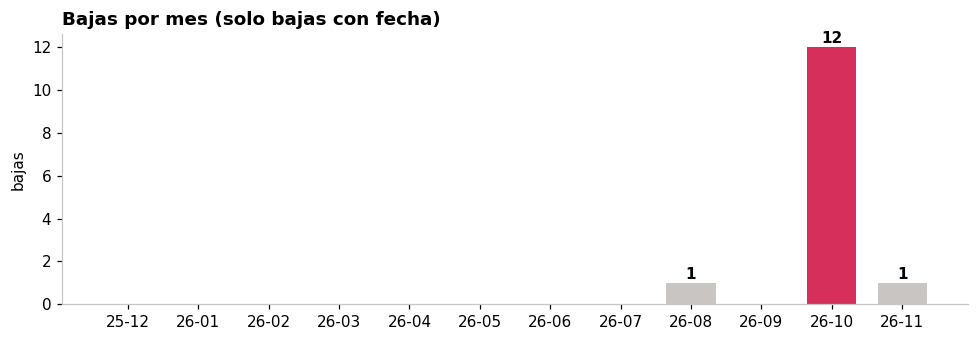

In [16]:
display(sql('SELECT * FROM v_rotacion_anual'))
rot = sql('SELECT * FROM v_rotacion_mensual')
fig, ax = plt.subplots(figsize=(9, 3.2))
ax.bar(rot.mes.str[2:], rot.bajas_mes, color=[CARMIN if v == rot.bajas_mes.max() else BRUMA for v in rot.bajas_mes], width=.7)
for x, v in enumerate(rot.bajas_mes):
    if v: ax.text(x, v + .2, int(v), ha='center', fontweight='bold')
ax.set_title('Bajas por mes (solo bajas con fecha)'); ax.set_ylabel('bajas'); plt.tight_layout(); plt.show()

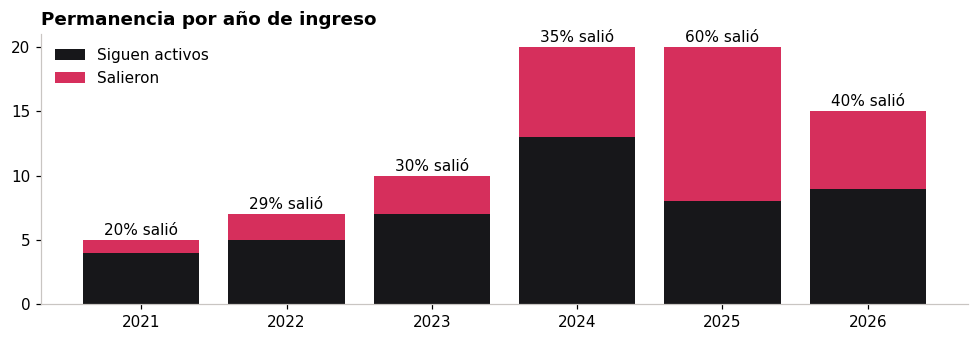

De quienes entraron desde 2024 ya salió el 45% (25 de 55).


,anio_ingreso,ingresos,activos,bajas,pct_baja,bajas_primer_anio,bajas_sin_dato_de_permanencia,permanencia_meses,bajas_con_permanencia
0,2021,5,4,1,20.0,NaN,1,NaN,0
1,2022,7,5,2,28.6,0.0,1,53.0,1
2,2023,10,7,3,30.0,0.0,2,34.0,1
3,2024,20,13,7,35.0,0.0,6,26.0,1
4,2025,20,8,12,60.0,1.0,5,14.3,6
5,2026,15,9,6,40.0,6.0,0,3.2,5


In [17]:
coh = sql('SELECT * FROM v_cohorte_ingreso WHERE anio_ingreso >= 2021')
fig, ax = plt.subplots(figsize=(9, 3.2))
ax.bar(coh.anio_ingreso.astype(str), coh.activos, color=TINTA, label='Siguen activos')
ax.bar(coh.anio_ingreso.astype(str), coh.bajas, bottom=coh.activos, color=CARMIN, label='Salieron')
for x, (a, b, p) in enumerate(zip(coh.activos, coh.bajas, coh.pct_baja)):
    ax.text(x, a + b + .4, f'{p:.0f}% salió', ha='center')
ax.set_title('Permanencia por año de ingreso'); ax.legend(frameon=False, loc='upper left'); plt.tight_layout(); plt.show()
d24 = coh[coh.anio_ingreso >= 2024]
print(f'De quienes entraron desde 2024 ya salió el {d24.bajas.sum() / d24.ingresos.sum() * 100:.0f}% ({d24.bajas.sum()} de {d24.ingresos.sum()}).')
coh

**Lectura:** la rotación anual medible subestima la real, porque más de la mitad de las bajas no tiene fecha.
Por cohorte no hace falta la fecha: basta el estatus. La causa de baja no existe en ningún registro, así que el *porqué* sigue sin respuesta.

### Asignación y utilización

In [18]:
display(sql('SELECT plantilla_activa, con_asignacion, en_banca, pct_en_banca, sobreasignados, personas_con_sueldo, banca_con_sueldo FROM v_utilizacion'))
display(sql('SELECT cliente, industria, colaboradores, concentracion_cliente_pct, pct_de_asignados FROM v_concentracion_cliente'))
sql('SELECT * FROM v_vencimiento_asignacion')

,plantilla_activa,con_asignacion,en_banca,pct_en_banca,sobreasignados,personas_con_sueldo,banca_con_sueldo
0,73,30,43,58.9,1,68,38


,cliente,industria,colaboradores,concentracion_cliente_pct,pct_de_asignados
0,Metalsa,Automotriz,23,31.5,76.7
1,Allegion,Manufactura,5,6.8,16.7
2,Grupo Daltile,Manufactura,3,4.1,10.0


,vence_en,asignaciones
0,31-60 días,3
1,Indefinida,24
2,Más de 90 días,4


**Lectura:** «en banca» incluye personal administrativo que no se asigna a clientes; separarlo requiere el departamento,
que falta en la mayoría de los activos. La concentración en un solo cliente es el riesgo comercial más visible.

### Costo

In [19]:
u = sql('SELECT * FROM v_utilizacion').iloc[0]
print(f'Costo de nómina al mes   : ${u.costo_nomina_mes:,.0f}  (sobre {int(u.personas_con_sueldo)} de {int(u.plantilla_activa)} activos con sueldo)')
print(f'Costo de la banca al mes : ${u.costo_banca_mes:,.0f}  ({u.costo_banca_mes / u.costo_nomina_mes * 100:.0f}% de la nómina; sobre {int(u.banca_con_sueldo)} con sueldo)')
# versión pública: el costo solo se muestra en esquemas con 5 o más personas
sql('SELECT esquema_nomina, personas, personas_con_sueldo, CASE WHEN personas_con_sueldo >= 5 THEN costo_nomina_por_esquema END AS costo_nomina_por_esquema FROM v_costo_por_esquema')

Costo de nómina al mes   : $3,836,939  (sobre 68 de 73 activos con sueldo)
Costo de la banca al mes : $1,912,228  (50% de la nómina; sobre 38 con sueldo)


,esquema_nomina,personas,personas_con_sueldo,costo_nomina_por_esquema
0,SMR,27,26,1227796.52
1,OTC 100%,14,13,827764.64
2,OTC-SINDICATO (SMR),10,10,638368.18
3,MAGNESON-SINDICATO,10,10,529747.01
4,XERES OT-SINDICATO,6,6,438642.60
5,MODALIDAD 40-SMR,3,3,NaN
6,IRAZU/ASIMILADOS,1,0,NaN
7,ADMINISTRATIVA,2,0,NaN


### Habilidades

In [20]:
display(sql('SELECT * FROM v_cobertura_matriz'))
print('Habilidades en riesgo de persona clave (≤ 1 experto disponible):')
sql('SELECT cod_habilidad, habilidad, tecnologia, evaluados, expertos_por_habilidad FROM v_expertos_por_habilidad WHERE riesgo_persona_clave = 1')

,plantilla_activa,con_matriz,sin_matriz,evaluaciones,evaluaciones_sin_fecha
0,73,47,26,1529,1529


Habilidades en riesgo de persona clave (≤ 1 experto disponible):


,cod_habilidad,habilidad,tecnologia,evaluados,expertos_por_habilidad
0,H0023,OPM,Oracle EBS,10,0
1,H0028,TALEO,Oracle EBS,7,0
2,H0049,OBI,Plataformas Tecnológicas,13,0
3,H0062,FUSE,Plataformas Tecnológicas,8,0
4,S0004,Empatia,Otros,0,0
5,S0005,Manejo de Conflictos,Otros,0,0
6,H0007,XTR,Oracle EBS,13,1
7,H0008,eBTAX,Oracle EBS,16,1
8,H0043,Landed Cost,Oracle Fusion Cloud,12,1
9,H0045,MFG (Cloud),Oracle Fusion Cloud,11,1


### Cumplimiento y activos

,plantilla_activa,expedientes_completos,pct_expediente_promedio,falta_puesto,falta_departamento,falta_esquema_nomina,falta_sueldo,cumple_regla_5
0,73,1,57.8,29,62,0,5,11


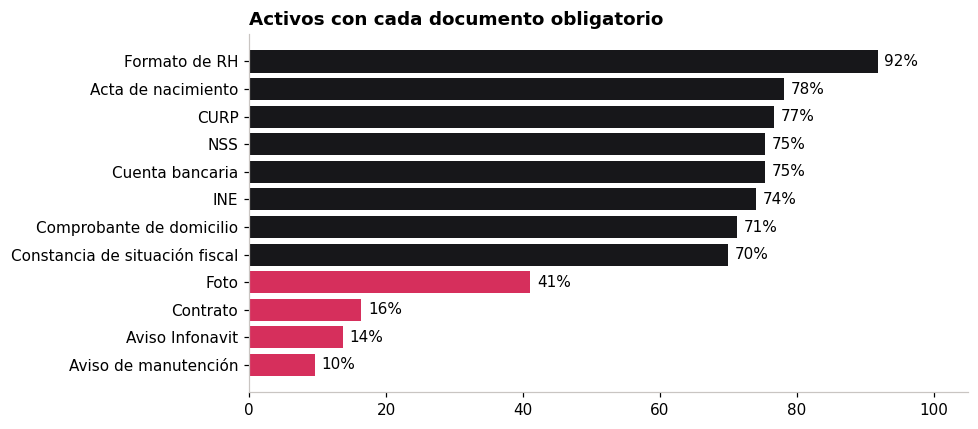

,equipos,en_uso,sin_asignar,sin_costo,pendientes_recuperar,pendientes_con_costo
0,123,81,32,70,9,4


In [21]:
display(sql('SELECT * FROM v_expediente_resumen'))
doc = sql('SELECT nombre, pct_cumplido FROM v_expediente_documento WHERE obligatorio = 1 ORDER BY pct_cumplido')
fig, ax = plt.subplots(figsize=(9, 4))
ax.barh(doc.nombre, doc.pct_cumplido, color=[CARMIN if v < 50 else TINTA for v in doc.pct_cumplido])
for y, v in enumerate(doc.pct_cumplido): ax.text(v + 1, y, f'{v:.0f}%', va='center')
ax.set_xlim(0, 105); ax.set_title('Activos con cada documento obligatorio'); plt.tight_layout(); plt.show()
sql('SELECT equipos, en_uso, sin_asignar, sin_costo, pendientes_recuperar, pendientes_con_costo FROM v_activos_resumen')

## 14. Lista de captura pendiente para RH
Campo exacto y tabla donde vive cada dato que falta.

In [22]:
sql('SELECT * FROM v_captura_pendiente')

,bloque,tabla,campo,descripcion,registros_faltantes,prioridad
0,Rotación,baja,id_causa_baja,Causa de baja de cada salida,32.0,Alta
1,Rotación,colaborador_acondicionado,fecha_baja,Fecha de baja,18.0,Alta
2,Rotación,colaborador_acondicionado,estatus,Activos que traían fecha de baja: confirmar si siguen,1.0,Alta
3,Utilización,registro_horas,horas · facturable,Horas por semana y asignación,31.0,Alta
4,Utilización,asignacion_acondicionada,fecha_inicio,Fecha real de inicio de la asignación,21.0,Media
5,Utilización,asignacion_acondicionada,pct_dedicacion,Porcentaje de dedicación (hoy estimado al 100%),31.0,Media
6,Utilización,asignacion_acondicionada,rol_asignado,Rol en el proyecto,29.0,Media
7,Costos,tarifa_proyecto,tarifa_hora,Tarifa por hora de cada proyecto,12.0,Alta
8,Costos,colaborador_acondicionado,sueldo_total_integrado,Sueldo de activos que hoy está en $0,5.0,Alta
9,Costos,proyecto_acondicionado,pm_otc,PM de OT Consulting del proyecto,6.0,Media


## 15. Conclusiones
- El pipeline corre de punta a punta sobre los archivos reales, **sin perder ni inventar registros**, y todas las validaciones dan cero.
- Lo que parecía completo no lo estaba: centinelas, fechas de relleno y montos en \$0 inflaban la completitud.
- Todas las tablas quedan unidas por ID. Las ligas por nombre y por texto se resolvieron una sola vez y quedaron en la bitácora.
- 17 atributos ya se calculan, 4 quedan parciales (dependen de la dedicación y del costo de equipo) y 6 están programados
  contra las tablas de extensión, listos para activarse.
- El siguiente paso es de captura, no de código: causa de baja, horas, tarifas, certificaciones y fecha de evaluación.

El tablero de la Etapa 4 (`tablero/`) lee estas mismas vistas.

In [23]:
con.close()